# Kunci Lab 02: bentuk fungsional model regresi



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita memilih bentuk hubungan yang sesuai. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan skala asli, logaritma, dan kurva melengkung.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")

Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})

## 1. Latihan: pendidikan dan pendapatan (log-lin)



<!-- kamus_variabel:pendidikan_pendapatan.csv -->

### Kenali data: Pendidikan dan pendapatan

**Data:** `data/pendidikan_pendapatan.csv`. **Satu baris:** satu responden.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Tahun_Pendidikan` | Total lama pendidikan yang telah ditempuh. | Tahun | X: penjelas |
| `Pendapatan_Tahunan` | Pendapatan yang diterima selama satu tahun. | Juta rupiah per tahun | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_pendapatan` | Logaritma alami dari Pendapatan_Tahunan. | Skala logaritma |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
didik = pd.read_csv(URL_DATA + "pendidikan_pendapatan.csv")

didik.head()

,Tahun_Pendidikan,Pendapatan_Tahunan
0,12,95.8
1,16,221.5
2,11,81.2
3,18,355.1
4,14,145.3


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
didik["ln_pendapatan"] = np.log(didik["Pendapatan_Tahunan"])

sampel_model_didik = didik[["ln_pendapatan", "Tahun_Pendidikan"]].dropna()
X_model_didik = sampel_model_didik[["Tahun_Pendidikan"]]
y_model_didik = sampel_model_didik["ln_pendapatan"]

In [5]:
model_didik = LinearRegression()
model_didik.fit(X_model_didik, y_model_didik)

koefisien_model_didik = pd.Series(model_didik.coef_, index=X_model_didik.columns)
koefisien_model_didik.loc["Intercept"] = model_didik.intercept_
print(koefisien_model_didik.round(4))
print(
    "Kenaikan pendapatan per tahun pendidikan (persen):",
    round(100 * koefisien_model_didik["Tahun_Pendidikan"], 2),
)

Tahun_Pendidikan    0.2139
Intercept           2.0264
dtype: float64
Kenaikan pendapatan per tahun pendidikan (persen): 21.39


### Lihat hasil model: Log pendapatan

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

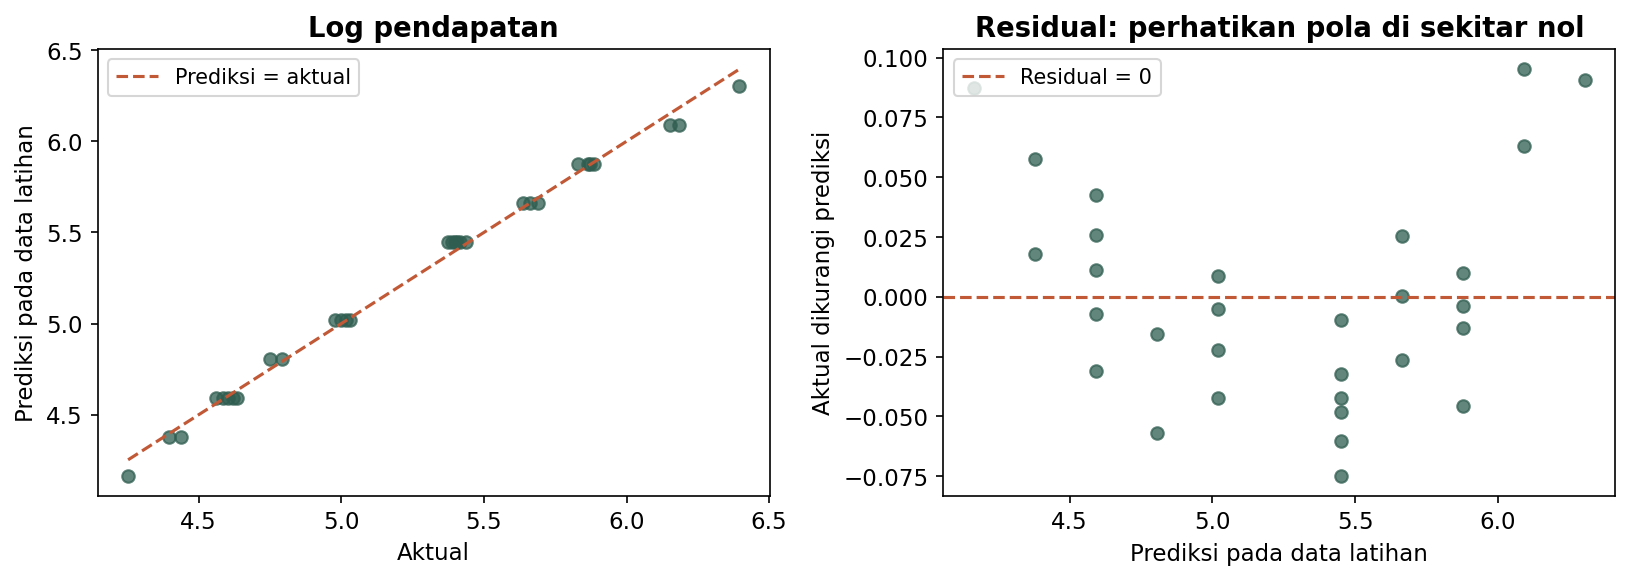

In [6]:
prediksi_visual = model_didik.predict(X_model_didik)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_didik, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_didik.min(), y_model_didik.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Log pendapatan")
axes[1].scatter(prediksi_visual, y_model_didik - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

In [7]:
# Pembanding: model linear biasa
sampel_model_linear = didik[["Pendapatan_Tahunan", "Tahun_Pendidikan"]].dropna()
X_model_linear = sampel_model_linear[["Tahun_Pendidikan"]]
y_model_linear = sampel_model_linear["Pendapatan_Tahunan"]

model_linear = LinearRegression()
model_linear.fit(X_model_linear, y_model_linear)
print("R2 log-lin:", round(model_didik.score(X_model_didik, y_model_didik), 4))
print("R2 linear :", round(model_linear.score(X_model_linear, y_model_linear), 4))

R2 log-lin: 0.9942
R2 linear : 0.8841


Kesimpulan: setiap tambahan satu tahun pendidikan menaikkan pendapatan
sekitar 21,4 persen menurut pendekatan 100 x beta. Perubahan eksaknya
adalah 100 x (exp(beta) - 1), sekitar 23,9 persen. Model log-lin memberi
interpretasi proporsional; periksa apakah ini sesuai teori dan residual.
R kuadrat 0,994 dan 0,884 tidak boleh dibandingkan langsung karena Y
pada model log-lin dan linear berada pada skala yang berbeda.



## 2. Latihan: usia dan kinerja (kuadratik)



<!-- kamus_variabel:usia_unit.csv -->

### Kenali data: Usia dan kinerja penjual

**Data:** `data/usia_unit.csv`. **Satu baris:** satu tenaga penjual.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Usia` | Umur tenaga penjual. | Tahun | X: penjelas |
| `Unit_Terjual` | Jumlah penjualan bulanan pada contoh kinerja penjual. | Unit per bulan, berupa angka simulasi | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `usia2` | Kuadrat usia: usia × usia. | Tahun kuadrat |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [8]:
usia = pd.read_csv(URL_DATA + "usia_unit.csv")

usia.head()

,Usia,Unit_Terjual
0,23,52.1
1,25,58.8
2,28,66.9
3,30,71.5
4,32,75.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [9]:
usia["usia2"] = usia["Usia"] ** 2

sampel_model_usia = usia[["Unit_Terjual", "Usia", "usia2"]].dropna()
X_model_usia = sampel_model_usia[["Usia", "usia2"]]
y_model_usia = sampel_model_usia["Unit_Terjual"]

In [10]:
model_usia = LinearRegression()
model_usia.fit(X_model_usia, y_model_usia)

koefisien_model_usia = pd.Series(model_usia.coef_, index=X_model_usia.columns)
koefisien_model_usia.loc["Intercept"] = model_usia.intercept_
print(koefisien_model_usia.round(3))

b1 = koefisien_model_usia["Usia"]
b2 = koefisien_model_usia["usia2"]
print("Usia puncak:", round(-b1 / (2 * b2), 2), "tahun")

Usia          8.642
usia2        -0.110
Intercept   -88.932
dtype: float64
Usia puncak: 39.46 tahun


### Lihat hasil model: Penjualan (unit sesuai data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

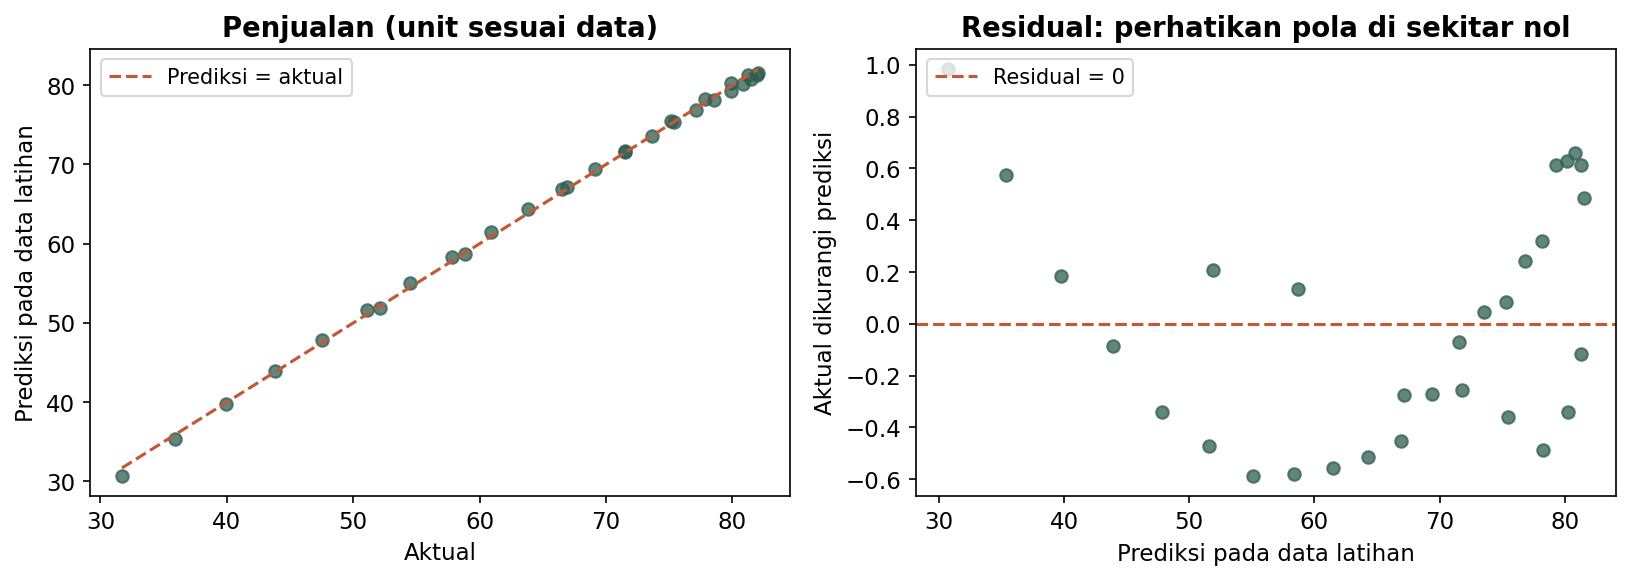

In [11]:
prediksi_visual = model_usia.predict(X_model_usia)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_usia, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_usia.min(), y_model_usia.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Penjualan (unit sesuai data)")
axes[1].scatter(prediksi_visual, y_model_usia - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

Kesimpulan: kinerja memuncak di usia sekitar 39,5 tahun. Koefisien `usia2`
negatif, itulah yang membuat kurva melengkung ke bawah.



## 3. Latihan: jam belajar dan skor (reciprocal)



<!-- kamus_variabel:jam_skor.csv -->

### Kenali data: Jam belajar dan hasil ujian

**Data:** `data/jam_skor.csv`. **Satu baris:** satu siswa/responden.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Jam_Belajar` | Total waktu belajar yang dicatat pada contoh. | Jam | X: penjelas |
| `Skor_Ujian` | Nilai/skor hasil ujian. | Poin skor; batas maksimum akan ditaksir dalam latihan | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `satu_per_jam` | Kebalikan jam belajar: 1 / Jam_Belajar. | Per jam |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [12]:
skor = pd.read_csv(URL_DATA + "jam_skor.csv")

skor.head()

,Jam_Belajar,Skor_Ujian
0,1,18.5
1,2,57.1
2,3,71.2
3,4,78.9
4,5,82.1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [13]:
skor["satu_per_jam"] = 1 / skor["Jam_Belajar"]

sampel_model_skor = skor[["Skor_Ujian", "satu_per_jam"]].dropna()
X_model_skor = sampel_model_skor[["satu_per_jam"]]
y_model_skor = sampel_model_skor["Skor_Ujian"]

In [14]:
model_skor = LinearRegression()
model_skor.fit(X_model_skor, y_model_skor)

koefisien_model_skor = pd.Series(model_skor.coef_, index=X_model_skor.columns)
koefisien_model_skor.loc["Intercept"] = model_skor.intercept_
print(koefisien_model_skor.round(2))

satu_per_jam   -82.55
Intercept       99.73
dtype: float64


### Lihat hasil model: Skor ujian (poin)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

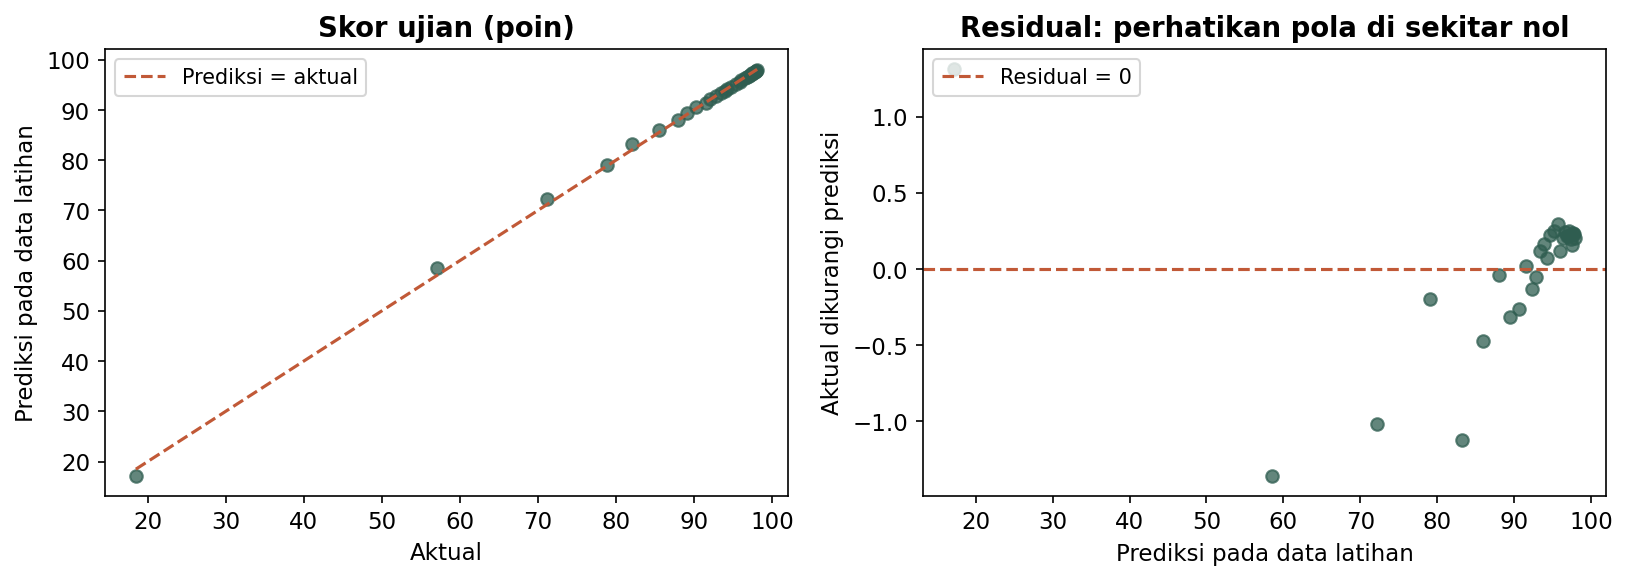

In [15]:
prediksi_visual = model_skor.predict(X_model_skor)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_skor, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_skor.min(), y_model_skor.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Skor ujian (poin)")
axes[1].scatter(prediksi_visual, y_model_skor - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

Kesimpulan: batas skor maksimal (asimtot) sekitar 99,7, dibaca dari
intersep. Koefisien `satu_per_jam` negatif dan besar, artinya tambahan
jam belajar membantu, tapi manfaatnya mengecil dan skor mendekati batas
99,7.



## 4. Latihan: memilih bentuk untuk data uts_1.csv



<!-- kamus_variabel:uts_1.csv -->

### Kenali data: Pertumbuhan ekonomi

**Data:** `data/uts_1.csv`. **Satu baris:** satu negara pada contoh 50 negara berkembang.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Pertumbuhan_Ekonomi` | Laju pertumbuhan kegiatan ekonomi/PDB. | Persen | Y: target |
| `X1_Investasi` | Besarnya investasi dibandingkan PDB. | Persen dari PDB | X: penjelas |
| `X2_Inflasi` | Laju kenaikan tingkat harga. | Persen | X: penjelas |
| `X3_Keterbukaan_Perdagangan` | Ukuran keterbukaan perdagangan relatif terhadap PDB. | Persen dari PDB | X: penjelas |

Rumus rinci ukuran keterbukaan tidak dicantumkan pada tabel sumber; jangan menganggapnya nilai ekspor saja.

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_y` | Logaritma alami pertumbuhan ekonomi yang bernilai positif. | Skala logaritma |
| `ln_inv` | Logaritma alami tingkat investasi. | Skala logaritma |
| `ln_inflasi` | Logaritma alami tingkat inflasi yang bernilai positif. | Skala logaritma |
| `ln_terbuka` | Logaritma alami ukuran keterbukaan perdagangan. | Skala logaritma |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [16]:
uts1 = pd.read_csv(URL_DATA + "uts_1.csv")

uts1.head()

,Y_Pertumbuhan_Ekonomi,X1_Investasi,X2_Inflasi,X3_Keterbukaan_Perdagangan
0,5.2,25.1,8.1,40.5
1,4.8,22.3,9.5,35.2
2,6.1,30.5,6.2,50.1
3,3.9,18.2,11.3,28.9
4,5.5,28.1,7.5,45.3


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [17]:
# Linear
sampel_model_lin = uts1[
    [
        "Y_Pertumbuhan_Ekonomi",
        "X1_Investasi",
        "X2_Inflasi",
        "X3_Keterbukaan_Perdagangan",
    ]
].dropna()
X_model_lin = sampel_model_lin[
    ["X1_Investasi", "X2_Inflasi", "X3_Keterbukaan_Perdagangan"]
]
y_model_lin = sampel_model_lin["Y_Pertumbuhan_Ekonomi"]

In [18]:
model_lin = LinearRegression()
model_lin.fit(X_model_lin, y_model_lin)

LinearRegression()

### Lihat hasil model: Pertumbuhan ekonomi (%)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

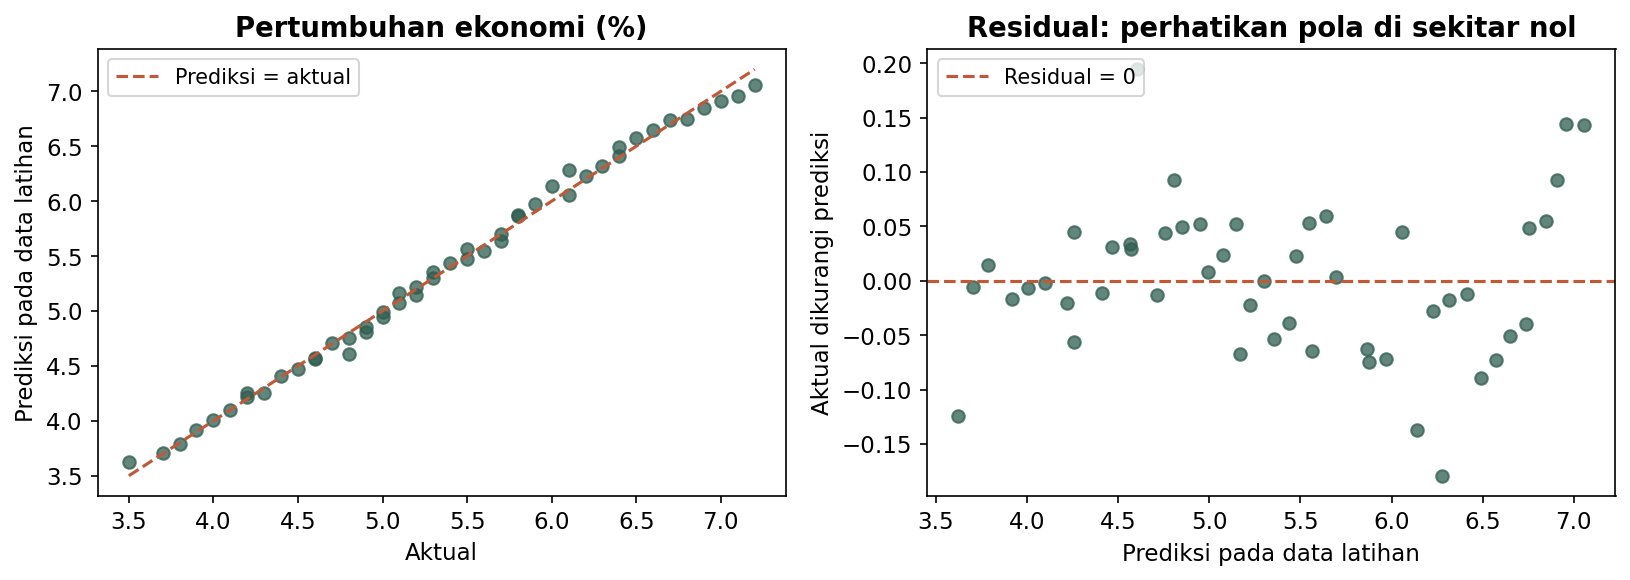

In [19]:
prediksi_visual = model_lin.predict(X_model_lin)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model_lin, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model_lin.min(), y_model_lin.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937", label="Prediksi = aktual")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Pertumbuhan ekonomi (%)")
axes[1].scatter(prediksi_visual, y_model_lin - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--", label="Residual = 0")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [20]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_lin = sm.OLS(
    y_model_lin,
    sm.add_constant(X_model_lin, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()

# Log-log
uts1["ln_y"] = np.log(uts1["Y_Pertumbuhan_Ekonomi"])
uts1["ln_inv"] = np.log(uts1["X1_Investasi"])
uts1["ln_inflasi"] = np.log(uts1["X2_Inflasi"])
uts1["ln_terbuka"] = np.log(uts1["X3_Keterbukaan_Perdagangan"])
sampel_model_log = uts1[["ln_y", "ln_inv", "ln_inflasi", "ln_terbuka"]].dropna()
X_model_log = sampel_model_log[["ln_inv", "ln_inflasi", "ln_terbuka"]]
y_model_log = sampel_model_log["ln_y"]

model_log = LinearRegression()
model_log.fit(X_model_log, y_model_log)

LinearRegression()

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [21]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_log = sm.OLS(
    y_model_log,
    sm.add_constant(X_model_log, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()

print("R2 linear:", round(model_lin.score(X_model_lin, y_model_lin), 4))
print("R2 log-log:", round(model_log.score(X_model_log, y_model_log), 4))
print("p-value linear:")
print(uji_model_lin.pvalues.round(4))
print("p-value log-log:")
print(uji_model_log.pvalues.round(4))

R2 linear: 0.9948
R2 log-log: 0.994
p-value linear:
Intercept                     0.0000
X1_Investasi                  0.3187
X2_Inflasi                    0.0012
X3_Keterbukaan_Perdagangan    0.0098
dtype: float64
p-value log-log:
Intercept     0.0011
ln_inv        0.3702
ln_inflasi    0.2259
ln_terbuka    0.0000
dtype: float64


Kesimpulan: kedua R kuadrat berada pada skala Y yang berbeda, sehingga
tidak digunakan sebagai dasar perbandingan langsung. Model linear menampilkan inflasi dan keterbukaan sebagai
signifikan; model log-log hanya keterbukaan. Pilihan terakhir tetap
bergantung teori: kalau ingin membaca elastisitas, pakai log-log.


## Selanjutnya

Kembali ke [Lab 02](https://colab.research.google.com/github/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/materi/02_latihan/02_bentuk_fungsional.ipynb) dan cocokkan langkah serta interpretasinya. Gunakan [panduan pengajar](https://github.com/akhiyarwaladi/ekonometrika_coding_workshop/blob/main/pengajar/README.md#pembahasan-latihan) untuk pembahasan bersama.